# Create computational mesh (pymesh2d)

Build a gradient-limited element-size field from GEBCO bathymetry and generate
the SnapWave unstructured mesh for the Samoa AoI.

**Prerequisites:** ``01_Generate_tif_From_GEBCO.ipynb`` (topobathy GeoTIFF and AoI).

## Configuration


In [1]:
import rioxarray

topobathy = rioxarray.open_rasterio("inputs/GRID/Samoa_300m.tif")
topobathy

<xarray.DataArray (band: 1, y: 838, x: 1713)> Size: 6MB
[1435494 values with dtype=float32]
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 7kB -12.87 -12.87 -12.87 ... -15.12 -15.12 -15.13
  * x            (x) float64 14kB -173.4 -173.4 -173.4 ... -168.8 -168.8 -168.8
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

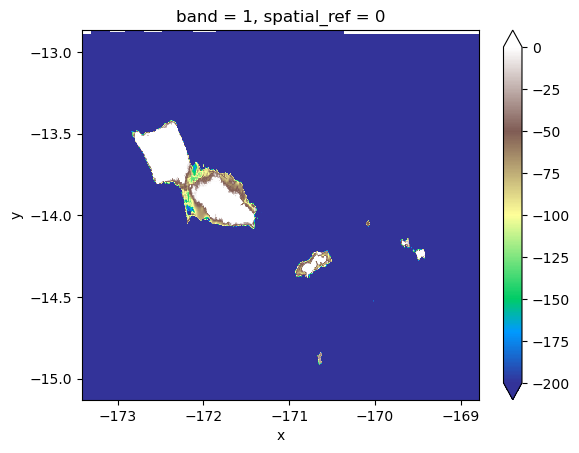

In [2]:
topobathy.plot(vmin=-200, vmax=0, cmap="terrain")

In [3]:
import pyproj
from pymesh2d.geom_util.proj_util import get_local_utm_crs

topobathy_crs = pyproj.CRS.from_epsg(4326)
utm_crs = get_local_utm_crs(topobathy_crs, topobathy.x, topobathy.y)

topobathy_crs, utm_crs

(<Geographic 2D CRS: EPSG:4326>
 Name: WGS 84
 Axis Info [ellipsoidal]:
 - Lat[north]: Geodetic latitude (degree)
 - Lon[east]: Geodetic longitude (degree)
 Area of Use:
 - name: World.
 - bounds: (-180.0, -90.0, 180.0, 90.0)
 Datum: World Geodetic System 1984 ensemble
 - Ellipsoid: WGS 84
 - Prime Meridian: Greenwich,
 <Projected CRS: PROJCS["UTM local",GEOGCS["WGS 84",DATUM["WGS_1984 ...>
 Name: UTM local
 Axis Info [cartesian]:
 - E[east]: Easting (metre)
 - N[north]: Northing (metre)
 Area of Use:
 - undefined
 Coordinate Operation:
 - name: unnamed
 - method: Transverse Mercator
 Datum: World Geodetic System 1984
 - Ellipsoid: WGS 84
 - Prime Meridian: Greenwich)

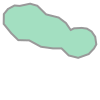

In [ ]:
import geopandas as gpd

aoi_polygon = gpd.read_file("inputs/AoI_Polygons/Samoa_AoI.shp").loc[0, "geometry"]
aoi_polygon

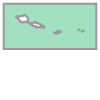

In [6]:
from pymesh2d.geom_util.getiso import getiso_polygone
from shapely import make_valid
from shapely.geometry import MultiPolygon

# Extract coastline (ocean area)
polygon_cost = getiso_polygone(
    topobathy.x, topobathy.y, topobathy.squeeze().values, zmax=0.0
)
# Extract the area of the domain
polygon_indef = getiso_polygone(
    topobathy.x, topobathy.y, topobathy.squeeze().values, zmax=5000
)

# Make the polygons valid
cost_mp = make_valid(MultiPolygon(polygon_cost)).buffer(0)
indef_mp = make_valid(MultiPolygon(polygon_indef)).buffer(0)

# Intersect the polygons to get the domain
topobathy_dominio = make_valid(cost_mp.intersection(indef_mp)).buffer(0)
# topobathy_dominio = max(topobathy_dominio_prev.geoms, key=lambda p: p.area)

topobathy_dominio

In [8]:
aoi_topobathy_polygon = aoi_polygon.intersection(topobathy_dominio)

# export aoi_topobathy_plygon
gdf = gpd.GeoDataFrame(geometry=[aoi_topobathy_polygon], crs=topobathy_crs)
gdf.to_file("inputs/AoI_Polygons/AoI_topobathy.shp")

<GeoAxes: title={'center': 'band = 1, spatial_ref = 0'}, xlabel='x', ylabel='y'>

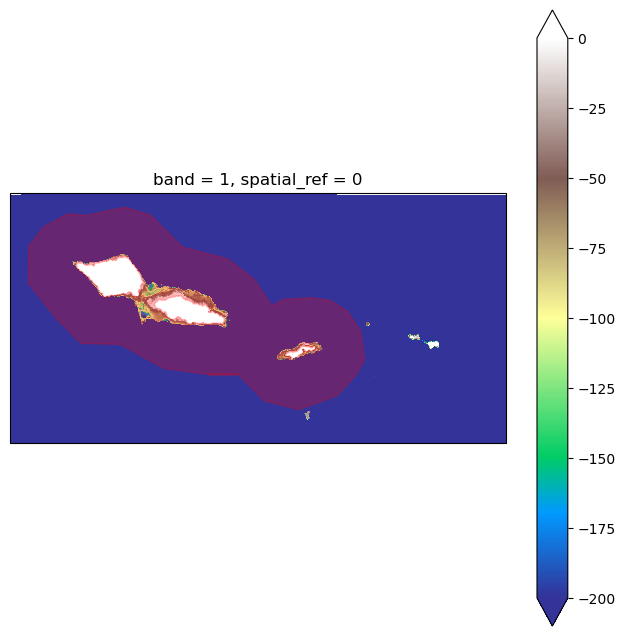

In [10]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": ccrs.PlateCarree()})

topobathy.plot(vmin=-200, vmax=0, cmap="terrain", ax=ax)
gdf.plot(ax=ax, color="red", alpha=0.25, edgecolor="red")

work_crs: PROJCS["UTM local",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",-13.997330644500002],PARAMETER["central_meridian",-171.104166667],PARAMETER["scale_factor",1],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1]]  |  grid_res: 600
brut: [100.0, 5000.0]  |  hfuns: [100.0, 5000.0]
réduction max: 4816.1


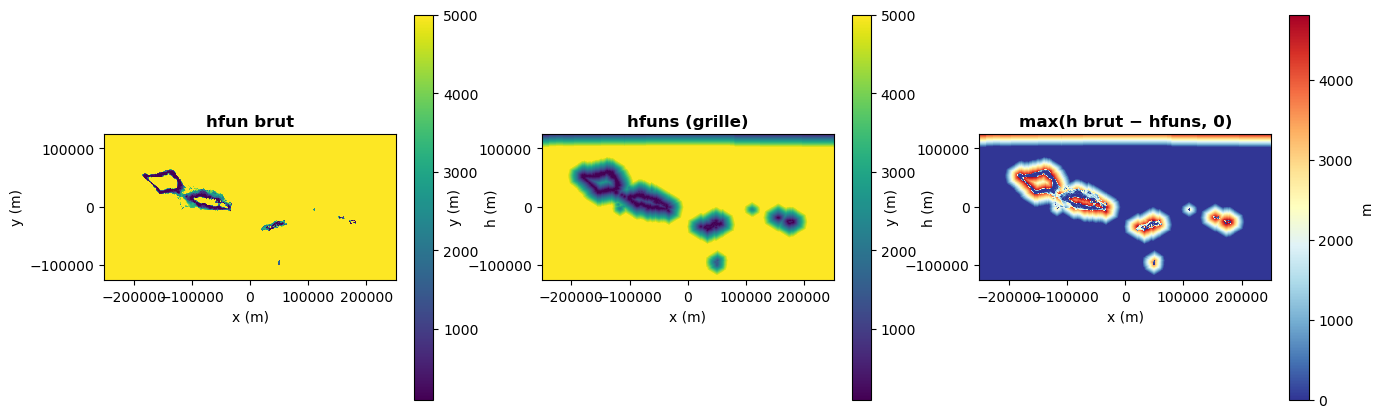

In [12]:
import numpy as np
from pymesh2d.geomesh_util.depth_field import depth_field_from_tif
from utils.hfunfun import plot_hfun, precalc_hfuns

depth_field = depth_field_from_tif("inputs/GRID/Samoa_300m.tif", utm_crs)


def hfun_depth_quadratic(test, depth_field, hmin=np.inf, hmax=np.inf):
    test = np.asarray(test, dtype=float)
    if test.ndim == 1:
        test = test.reshape(1, -1)

    h = depth_field(test) if callable(depth_field) else np.asarray(depth_field)
    if np.size(h) == 1:
        h_scalar = float(np.asarray(h).reshape(-1)[0])
        h = np.full(test.shape[0], h_scalar)
    else:
        h = np.asarray(h).reshape(-1)
        if h.shape[0] != test.shape[0]:
            raise ValueError("depth_field size must match test points")

    hfun_values = 0.14 * h**2 + 28 * h + 655
    return np.clip(hfun_values, hmin, hmax)


def hfun(test):
    return hfun_depth_quadratic(test, depth_field, hmin=100, hmax=5000)


hfuns = precalc_hfuns(
    hfun, work_crs=utm_crs, lon=topobathy.x, lat=topobathy.y, geo_crs=topobathy_crs
)
plot_hfun(hfuns, hfun);

In [13]:
from pymesh2d.geom_util.proj_util import reproject_geometry

domain_UTM = reproject_geometry(aoi_topobathy_polygon, topobathy_crs, utm_crs)

if domain_UTM.geom_type == "MultiPolygon":
    largest_polygon_domain_UTM = max(domain_UTM.geoms, key=lambda p: p.area)
else:
    largest_polygon_domain_UTM = domain_UTM

In [14]:
from pymesh2d.geom_util.poly_util import polygon_to_node_edge, resample_polygon_hfun
from pymesh2d.geomesh_util.border_util import clean_polygon

# Use smoothed sizing function directly
poly_comput_UTM = resample_polygon_hfun(largest_polygon_domain_UTM, hfuns)

if poly_comput_UTM.geom_type == "MultiPolygon":
    poly_comput_UTM = max(poly_comput_UTM.geoms, key=lambda p: p.area)

poly_comput_UTM_clean = clean_polygon(poly_comput_UTM, min_vertices=15)

# Convert to nodes and edges
node_c, edge_c = polygon_to_node_edge(poly_comput_UTM_clean)

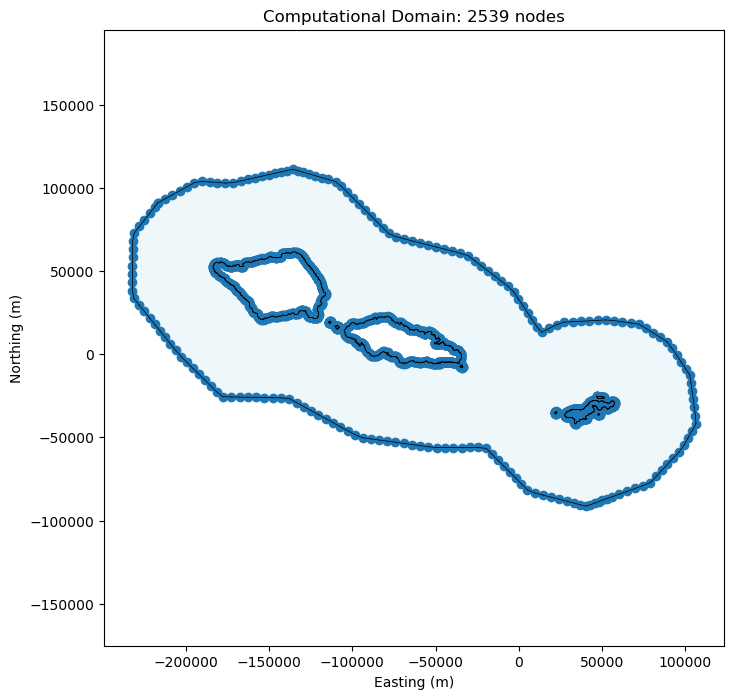

In [15]:
from shapely.plotting import plot_polygon

fig, ax = plt.subplots(figsize=(8, 8))
plot_polygon(poly_comput_UTM_clean, ax=ax, facecolor="lightblue", alpha=0.2)

for e in edge_c.astype(int):
    ax.plot(node_c[e, 0], node_c[e, 1], "k-", lw=0.5)
ax.scatter(node_c[:, 0], node_c[:, 1], color="red", s=2)

ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_title(f"Computational Domain: {len(node_c)} nodes")
ax.axis("equal");

In [16]:
from pymesh2d.refine import refine

# Mesh generation options
opts_refine = {"kind": "delaunay"}

# Generate and smooth computational mesh
vert_c, etri_c, tria_c, tnum_c = refine(node_c, edge_c, [], opts_refine, hfuns)


 Refine triangulation...

 -------------------------------------------------------
      |ITER.|          |CDT1(X)|          |CDT2(X)|     
 -------------------------------------------------------
          3               2575               2555
         10               2577               5611
         20               2637              26683
         30               2653              29059
         36               2656              29122



In [17]:
from pymesh2d.smooth import smooth

opts_smooth = {}

vert_c, etri_c, tria_c, tnum_c = smooth(
    vert_c, etri_c, tria_c, tnum_c, opts_smooth, hfuns
)


 Smooth triangulation...

 -------------------------------------------------------
      |ITER.|          |MOVE(X)|          |DTRI(X)|     
 -------------------------------------------------------
          0              12691              28544
          4              10711              26882
          8               6879              26560
         12               4392              26488
         16               3472              26490
         20               2899              26456
         24               2544              26522
         28               2374              26490



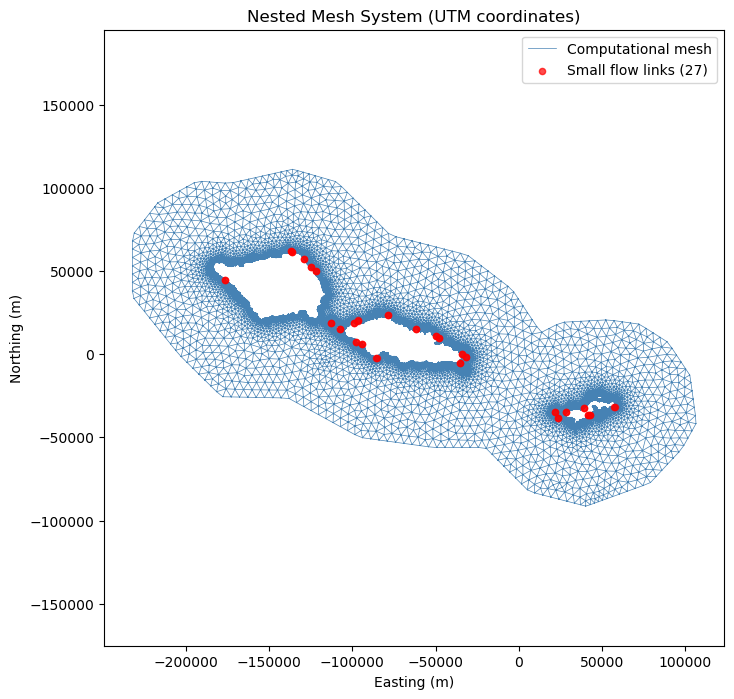

In [18]:
from pymesh2d.mesh_util.circo import small_flow_centers
from pymesh2d.mesh_util.tricon import tricon

# Compute triangle connectivity and identify small flow links
edge_cc, _ = tricon(tria_c, None)

circumcenters, nlinktoosmall = small_flow_centers(
    vert_c, tria_c, edge_cc, removesmalllinkstrsh=0.11, conn=None
)

# Visualize both meshes
fig, ax = plt.subplots(figsize=(8, 8))

ax.triplot(
    vert_c[:, 0],
    vert_c[:, 1],
    tria_c[:, 0:3],
    color="steelblue",
    lw=0.5,
    label="Computational mesh",
)

if nlinktoosmall > 0:
    ax.scatter(
        circumcenters[:, 0],
        circumcenters[:, 1],
        color="red",
        s=20,
        alpha=0.7,
        zorder=5,
        label=f"Small flow links ({nlinktoosmall})",
    )
else:
    ax.text(
        0.02,
        0.98,
        "No small flow links detected",
        transform=ax.transAxes,
        fontsize=12,
        color="green",
        verticalalignment="top",
    )

ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_title("Nested Mesh System (UTM coordinates)")
ax.legend()
ax.axis("equal");

In [19]:
from pymesh2d.geom_util.proj_util import reproject_node
from pymesh2d.smood import smood

vvert_c = reproject_node(
    vert_c, get_local_utm_crs(topobathy_crs, topobathy.x, topobathy.y), topobathy_crs
)

vert_2, etri_2, tria_2, tnum_2 = smood(
    vvert_c,
    etri_c,
    tria_c,
    tnum_c,
    opts={
        "strategy": "continuous",
        "require_both_criteria": True,
        "iter": 24,
        "max_adapt_steps": 12,
        "continuous_stagnation_patience": 2,
        "preserve_merged_quads": True,
    },
)


 Smooth triangulation for Delft3D-FM computation...

 -------------------------------------------------------
      |STATE.|      |MAX|COS(PHI)| |N_SMALL| |N_ZONES|
 -------------------------------------------------------
    initial         0.584510            28          0
    outer=0         1.000000             0         39
    outer=1         1.000000             0         87
    outer=2         1.000000             0         94
    outer=3         1.000000             0         96
    outer=4         1.000000             0        100


KeyboardInterrupt: 

In [20]:
from pymesh2d.geomesh_util.interpolation_mesh import interpolate_from_tiff

z = interpolate_from_tiff(
    "inputs/GRID/Samoa_300m.tif", vvert_c, input_crs=topobathy_crs
)

In [21]:
from pymesh2d.geomesh_util.grd_util import adcirc2DFlowFM

ds_out = adcirc2DFlowFM(np.column_stack((vvert_c, z)), tria_c)

In [22]:
ds_out.to_netcdf("inputs/GRID/Samoa_mesh.nc")